# Défi NLP medRxiv 2026, projet 2 : détection des abstracts générés par une IA
## Script 2 : modèles de langage neuronaux (PyTorch + Hugging Face)

**Contexte :** de plus en plus de textes scientifiques sont écrits par des modèles de langage (LLM). Le jeu de données mélange des abstracts de preprints déposés sur medRxiv entre mars et septembre 2026 et des abstracts générés par plusieurs LLM à partir du titre et de l'abstract d'un vrai preprint. Le script 1 utilisait des représentations classiques (TF-IDF, stylométrie), ici on passe à des modèles de langage pré-entraînés.

**Objectif :** prédire si un abstract a été écrit par un humain (**0**) ou généré par une IA (**1**).

On teste deux approches :
* **A. Perplexité GPT-2.** Un texte généré par une IA est en général plus prévisible pour un autre modèle de langage. On calcule quelques variables avec GPT-2, sans le réentraîner, et on les donne à une régression logistique.
* **B. Fine-tuning de RoBERTa.** On ajoute une tête de classification (2 classes) à un encodeur pré-entraîné et on réentraîne tout le réseau sur nos abstracts, avec une perte pondérée pour le déséquilibre. C'est l'architecture des « détecteurs RoBERTa » de texte généré.

Le meilleur des deux sert de modèle final pour prédire le fichier de test. On le compare aussi au modèle final du script 1, sur les mêmes abstracts.

Pour l'évaluation, on met de côté un jeu de validation stratifié de 20 %, pris dans le jeu d'entraînement seul, qui sert uniquement à mesurer les performances à la fin. Les choix (meilleure époque, seuils de décision) sont faits sur un petit jeu de réglage séparé, 10 % de l'apprentissage restant, pour que le F1 de validation soit une estimation indépendante. Une validation croisée à 5 plis serait plus rigoureuse, mais elle multiplierait par 5 le temps de fine-tuning.


importer "ClassificationsHumanAI_AbstractsTrainSet.csv.gz" et "ClassificationsHumanAI_AbstractsTestSet.csv.gz"
(et pour la comparaison avec le script 1, le fichier "probas_hors_pli_script1.csv" produit par le script 1, mais le script fonctionne sans)

Plan :
 1. GPU et graines aléatoires
 2. données, jeu de réglage et jeu de validation
 3. approche A, perplexité GPT-2
 4. approche B, fine-tuning de RoBERTa
 5. comparaison avec le script 1 et graphiques
 6. prédiction du fichier de test
 7. conclusion

In [ ]:
import pandas as pd
import numpy as np
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   


fichier_donnees = "ClassificationsHumanAI_AbstractsTrainSet.csv.gz"   #données d'apprentissage
fichier_test = "ClassificationsHumanAI_AbstractsTestSet.csv.gz"       #fichier à prédire
fichier_sortie = "groupe4_asas_elbacha_saad_saoudi_leyenbeger_engin.csv"     #fichier de prédictions (ID, pred)
fichier_probas_script1 = "probas_hors_pli_script1.csv"                #probabilités du script 1 (pour comparer les 2 scripts)
dossier_figures = "figures_script2"                                   #figures et tableaux
os.makedirs(dossier_figures, exist_ok=True)

ENCODEUR = "roberta-base"   #encodeur à ajuster (nom Hugging Face)
MODELE_LM = "gpt2"          #modèle de langage pour la perplexité
N_EPOQUES = 3               #nombre de passages sur le jeu d'apprentissage
MODE_RAPIDE = False         #mettre True pour un test rapide sur un sous-échantillon (vérifier que le code tourne)
GRAINE = 42                 #graine aléatoire, pour avoir des résultats reproductibles
COL_LABEL = "HumanAI"       #variable à prédire (0 = humain, 1 = IA)
MAX_LEN = 512               #limite des modèles de type BERT/RoBERTa (voir étape 4)
TAILLE_LOT = 16             #nombre d'abstracts par lot (batch)
LR = 2e-5                   #pas d'apprentissage classique pour le fine-tuning de BERT/RoBERTa

## 1. GPU et graines aléatoires
* On fixe les graines aléatoires pour obtenir (à peu près) toujours les mêmes résultats.
* On utilise le GPU s'il y en a un. Sur GPU, les calculs se font en demi-précision (float16), ce qui va environ 2x plus vite.

In [2]:
import torch   #PyTorch (tenseurs, réseaux de neurones, GPU)

def fixer_graines(g):
    np.random.seed(g); torch.manual_seed(g); torch.cuda.manual_seed_all(g)
fixer_graines(GRAINE)

appareil = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = appareil.type == "cuda"   #demi-précision (float16) seulement sur GPU
print(f"Appareil utilisé : {appareil}" + ("" if AMP else "  (pas de GPU : ce sera LENT)"))

Appareil utilisé : cuda


## 2. données, jeu de réglage et jeu de validation
* On reprend le même chargement et le même nettoyage léger que dans le script 1, donc on garde la ponctuation, les majuscules et la mise en forme. Le tokenizer de RoBERTa (BPE au niveau des octets) conserve d'ailleurs tous les caractères, y compris les tirets longs et les espaces.
* Les abstracts vides sont classés IA par la règle (100 % IA dans le train, voir le script 1), et les doublons exacts sont retirés pour que la validation ne soit pas trop optimiste.
* On met de côté un **jeu de validation de 20 %**, stratifié (même part d'IA), qui sert seulement à évaluer et comparer les modèles à la fin.
* On prend aussi un **jeu de réglage**, 10 % de l'apprentissage restant (671 abstracts), qui sert à faire les choix, la meilleure époque de RoBERTa et les seuils de décision. Comme ces choix ne sont pas faits sur la validation, le F1 de validation n'est pas optimiste. RoBERTa est donc entraîné sur 6 039 abstracts.

In [3]:
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

def charger(chemin):
    df = pd.read_csv(chemin, sep=";")
    df["abstract"] = df["abstract"].fillna("").astype(str)
    return df

def nettoyer(texte):
    #nettoyage léger comme dans le script 1, seulement les balises HTML et les espaces au début et à la fin
    return re.sub(r"<[^>]+>", " ", texte).strip()

train = charger(fichier_donnees)
test = charger(fichier_test)
train["texte"] = train["abstract"].map(nettoyer)
test["texte"] = test["abstract"].map(nettoyer)

#sans les vides (règle vide = IA) et sans les doublons exacts
donnees = (train[train["texte"] != ""]
           .drop_duplicates(subset="texte")
           .reset_index(drop=True))

#jeu de validation tenu à l'écart (20 %, stratifié), il sert seulement à évaluer les modèles
idx_app, idx_val = train_test_split(np.arange(len(donnees)), test_size=0.2,
                                    stratify=donnees[COL_LABEL], random_state=GRAINE)
#jeu de réglage (10 % de l'apprentissage), il sert à choisir l'époque et les seuils
idx_app, idx_regl = train_test_split(idx_app, test_size=0.1,
                                     stratify=donnees[COL_LABEL].values[idx_app], random_state=GRAINE)
if MODE_RAPIDE:   #mode test avec un petit sous-échantillon et 1 époque
    idx_app, idx_regl, idx_val = idx_app[:600], idx_regl[:200], idx_val[:200]
    N_EPOQUES = 1
app = donnees.iloc[idx_app].reset_index(drop=True)
regl = donnees.iloc[idx_regl].reset_index(drop=True)
val = donnees.iloc[idx_val].reset_index(drop=True)
y_app, y_regl, y_val = app[COL_LABEL].values, regl[COL_LABEL].values, val[COL_LABEL].values
print(f"Apprentissage : {len(app)} | Réglage : {len(regl)} | Validation : {len(val)} | Test : {len(test)}")

def meilleur_seuil(y_, proba):
    #seuil de décision qui maximise le F1 (choisi sur le jeu de réglage)
    seuils = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = [f1_score(y_, (proba >= s).astype(int)) for s in seuils]
    i = int(np.argmax(f1s))
    return seuils[i], f1s[i]

def scores(nom, y_, proba, seuil):
    pred = (proba >= seuil).astype(int)
    return {"modèle": nom, "seuil": seuil, "F1": f1_score(y_, pred),
            "précision": precision_score(y_, pred, zero_division=0),
            "rappel": recall_score(y_, pred), "AUC": roc_auc_score(y_, proba)}

resultats = []      #tableau comparatif

Apprentissage : 6039 | Réglage : 671 | Validation : 1678 | Test : 2898


## 3. approche A, variables de perplexité calculées avec GPT-2
Pour chaque mot (token) du texte, GPT-2 donne la probabilité qu'il avait de prédire ce mot à partir des mots précédents. On en tire 5 variables :
* `log_perplexite`, la moyenne de -log p(token) (plus elle est faible, plus le texte est prévisible)
* `ecart_type_logp`, la variabilité de la surprise d'un token à l'autre. C'est la « burstiness », les humains alternent mots attendus et inattendus alors que les IA sont plus régulières
* `surprise_max`, le token le plus inattendu
* `part_top1` et `part_top10`, la part des tokens qui étaient le 1er choix ou dans les 10 premiers choix de GPT-2 (idée du détecteur GLTR)

GPT-2 n'est pas réentraîné (`torch.no_grad()`). On s'en sert seulement pour calculer ces variables, qu'on donne ensuite à une régression logistique.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM   #Hugging Face, modèles pré-entraînés
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()        #masque les avertissements verbeux de transformers

print(f"Approche A : chargement de {MODELE_LM}...")
tok_lm = AutoTokenizer.from_pretrained(MODELE_LM)
lm = AutoModelForCausalLM.from_pretrained(MODELE_LM).to(appareil).eval()

tok_lm.pad_token = tok_lm.eos_token   #GPT-2 n'a pas de token de remplissage, on réutilise le token de fin
tok_lm.padding_side = "right"
TAILLE_LOT_LM = 8                      #abstracts traités ensemble par GPT-2

@torch.no_grad()        #pas de calcul de gradient car on n'entraîne pas GPT-2
def variables_perplexite_lot(textes):
    #les 5 variables pour un lot de textes (même calcul que texte par texte, mais plus rapide)
    enc = tok_lm(list(textes), return_tensors="pt", truncation=True, max_length=1024,
                 padding=True).to(appareil)                 #GPT-2 accepte 1 024 tokens 
    logits = lm(**enc).logits[:, :-1].float()               #prédiction du token suivant
    cibles = enc.input_ids[:, 1:]                           #tokens réellement présents
    masque = enc.attention_mask[:, 1:].bool()               #pour ignorer les tokens de remplissage
    log_p = torch.log_softmax(logits, dim=-1)
    lp = log_p.gather(2, cibles[..., None]).squeeze(2)      #log p(token réel)
    rang = (log_p > lp[..., None]).sum(2)                   #rang du token réel (0 = 1er choix)
    lignes = []
    for k in range(len(textes)):
        l, r = lp[k][masque[k]], rang[k][masque[k]]         #seulement les vrais tokens du texte k
        lignes.append([(-l.mean()).item(), l.std().item(), (-l.min()).item(),
                       (r == 0).float().mean().item(), (r < 10).float().mean().item()])
    return lignes

NOMS_PPL = ["log_perplexite", "ecart_type_logp", "surprise_max", "part_top1", "part_top10"]
def tableau_perplexite(textes):
    textes = list(textes)
    n_tokens = [len(ids) for ids in tok_lm(textes, truncation=True, max_length=1024)["input_ids"]]
    lignes = [[np.nan] * 5 for _ in textes]                 #les textes trop courts (moins de 3 tokens) gardent NaN
    #on regroupe les textes de longueur proche pour limiter le remplissage
    ordre = [i for i in np.argsort(n_tokens) if n_tokens[i] >= 3]
    for debut in range(0, len(ordre), TAILLE_LOT_LM):
        lot = ordre[debut:debut + TAILLE_LOT_LM]
        for i, v in zip(lot, variables_perplexite_lot([textes[i] for i in lot])):
            lignes[i] = v
        if (debut // TAILLE_LOT_LM + 1) % 125 == 0:
            print(f"   {debut + len(lot)}/{len(ordre)} textes")
    return pd.DataFrame(lignes, columns=NOMS_PPL).fillna(0)

P_app = tableau_perplexite(app["texte"])
P_val = tableau_perplexite(val["texte"])
P_regl = tableau_perplexite(regl["texte"])
print("Variables de perplexité calculées. Moyennes par classe (apprentissage) :")
print(P_app.groupby(y_app).mean().T.rename(columns={0: "humain", 1: "IA"}).round(3).to_string())

Approche A : chargement de gpt2...


   1000/6038 textes
   2000/6038 textes
   3000/6038 textes
   4000/6038 textes
   5000/6038 textes
   6000/6038 textes
   1000/1678 textes
Variables de perplexité calculées. Moyennes par classe (apprentissage) :
                 humain      IA
log_perplexite    3.315   3.244
ecart_type_logp   3.082   3.011
surprise_max     15.571  14.762
part_top1         0.407   0.410
part_top10        0.683   0.691


Il faut faire attention à l'interprétation. Les textes humains contiennent aussi des artefacts de collecte (titres collés "MethodsWe", apostrophes supprimées) qui surprennent GPT-2 et augmentent leur perplexité. La perplexité mesure donc à la fois le style et ces artefacts.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler       #centre-réduit les variables
from sklearn.linear_model import LogisticRegression

#régression logistique sur les 5 variables GPT-2 (class_weight compense le déséquilibre)
clf_ppl = make_pipeline(StandardScaler(),
                        LogisticRegression(class_weight="balanced", max_iter=1000))
clf_ppl.fit(P_app, y_app)
proba_val_ppl = clf_ppl.predict_proba(P_val)[:, 1]
proba_regl_ppl = clf_ppl.predict_proba(P_regl)[:, 1]
s_ppl, _ = meilleur_seuil(y_regl, proba_regl_ppl)      #seuil choisi sur le jeu de réglage
resultats.append(scores("A. Perplexité GPT-2 + LR", y_val, proba_val_ppl, s_ppl))
print(resultats[-1])

del lm                                   #libère la mémoire du GPU
if AMP:
    torch.cuda.empty_cache()

{'modèle': 'A. Perplexité GPT-2 + LR', 'seuil': np.float64(0.49), 'F1': 0.40660165041260315, 'précision': 0.29714912280701755, 'rappel': 0.6437054631828979, 'AUC': np.float64(0.6035502846765949)}


## 4. approche B, fine-tuning de RoBERTa
On a choisi l'encodeur `roberta-base` plutôt qu'un modèle biomédical comme PubMedBERT ou BioBERT, pour trois raisons :
* on cherche à reconnaître une façon d'écrire, pas un contenu médical
* PubMedBERT et BioBERT sont « uncased », leur tokenizer met tout en minuscules et retire les accents et caractères spéciaux, donc il efface une partie des indices typographiques
* les détecteurs de texte généré publiés sont souvent basés sur RoBERTa

On peut tester un autre encodeur en changeant `ENCODEUR` dans la première cellule (par exemple `"distilroberta-base"`, plus rapide, ou `"microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract"`).

Les modèles de type BERT ne lisent que **512 tokens** au maximum. On regarde d'abord combien d'abstracts dépassent cette limite.


In [6]:
print(f"Approche B : fine-tuning de {ENCODEUR}")
tokenizer = AutoTokenizer.from_pretrained(ENCODEUR)

#combien d'abstracts dépassent 512 tokens?
longueurs = np.array([len(ids) for ids in tokenizer(list(app["texte"]))["input_ids"]])
print(f"Longueur en tokens : médiane {np.median(longueurs):.0f}, "
      f"90e centile {np.percentile(longueurs, 90):.0f}, "
      f"{(longueurs > MAX_LEN).mean():.1%} des abstracts dépassent {MAX_LEN}")

Approche B : fine-tuning de roberta-base
Longueur en tokens : médiane 410, 90e centile 652, 26.4% des abstracts dépassent 512


* Sur nos données, un abstract fait en médiane environ 410 tokens, et **environ 26 % des abstracts dépassent 512 tokens** (surtout des abstracts humains, qui sont plus longs). Pour ceux qui dépassent, on perd la fin du texte (fin des Results et Conclusions).
* On a choisi la **troncature**, on garde les 512 premiers tokens. Plusieurs raisons à ça :
  * les indices de style (vocabulaire, tournures, ponctuation, titres de section) sont présents dès le début du texte (Background, Methods), et 512 tokens suffisent pour reconnaître une façon d'écrire
  * la troncature efface une information, la longueur (les abstracts humains sont plus souvent longs), mais c'est un indice secondaire (dans le script 1, le nombre de mots seul a une AUC de 0,56 seulement)
  * c'est la solution la plus simple et la moins coûteuse en temps de GPU
* Il existe d'autres possibilités, comme garder le début et la fin du texte (par exemple les 128 premiers et les 382 derniers tokens, la meilleure stratégie dans Sun et al., 2019, *How to Fine-Tune BERT for Text Classification?*) ou découper le texte en morceaux de 512 tokens et moyenner les probabilités (plus coûteux).
* Pour GPT-2 (approche A), la limite est de 1 024 tokens.
* `DataCollatorWithPadding` complète chaque lot à la longueur du plus long texte du lot (et pas à 512 pour tous), ce qui est beaucoup plus rapide.

In [7]:
from torch.utils.data import Dataset, DataLoader    #découpage des données en lots
from transformers import DataCollatorWithPadding

class JeuAbstracts(Dataset):
    #jeu de données PyTorch, transforme le texte en identifiants de tokens (+ étiquette)
    def __init__(self, textes, etiquettes=None):
        self.enc = tokenizer(list(textes), truncation=True, max_length=MAX_LEN)
        self.etiquettes = etiquettes
    def __len__(self):
        return len(self.enc["input_ids"])
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        if self.etiquettes is not None:
            item["labels"] = int(self.etiquettes[i])
        return item

assembleur = DataCollatorWithPadding(tokenizer)
lots_app = DataLoader(JeuAbstracts(app["texte"], y_app), batch_size=TAILLE_LOT,
                      shuffle=True, collate_fn=assembleur)

@torch.no_grad()
def predire_probas(modele, textes):
    #probabilité d'être IA pour une liste de textes
    modele.eval()
    lots = DataLoader(JeuAbstracts(textes), batch_size=2 * TAILLE_LOT, collate_fn=assembleur)
    sorties = []
    for lot in lots:
        lot = {k: v.to(appareil) for k, v in lot.items()}
        with torch.autocast(device_type=appareil.type, dtype=torch.float16, enabled=AMP):
            logits = modele(**lot).logits
        sorties.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(sorties).numpy()

Pour le modèle, la perte et l'optimiseur :
* on part de l'encodeur pré-entraîné et on ajoute une tête de classification à 2 sorties
* on utilise une **perte pondérée**, avec des poids inversement proportionnels à l'effectif de chaque classe. Avec nos effectifs, le poids d'un abstract IA (classe rare) est d'environ 2 (1,99) et celui d'un humain d'environ 0,67, donc une erreur sur une IA compte environ 3 fois plus qu'une erreur sur un humain. C'est la même idée que `class_weight="balanced"`
* l'optimiseur est AdamW, avec un pas d'apprentissage qui monte pendant 6 % des étapes (« warm-up ») puis décroît linéairement jusqu'à 0, c'est le réglage standard pour BERT et RoBERTa

In [8]:
import torch.nn as nn    #couches et fonctions de perte de PyTorch
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

fixer_graines(GRAINE)
modele = AutoModelForSequenceClassification.from_pretrained(ENCODEUR, num_labels=2).to(appareil)

#perte pondérée
effectifs = np.bincount(y_app, minlength=2)
poids = torch.tensor(len(y_app) / (2 * effectifs), dtype=torch.float32, device=appareil)
print(f"Poids des classes dans la perte : humain {poids[0]:.2f} | IA {poids[1]:.2f}")
fonction_perte = nn.CrossEntropyLoss(weight=poids)

#optimiseur et planification du pas d'apprentissage
optimiseur = torch.optim.AdamW(modele.parameters(), lr=LR, weight_decay=0.01)
n_etapes = N_EPOQUES * len(lots_app)
planificateur = get_linear_schedule_with_warmup(optimiseur, int(0.06 * n_etapes), n_etapes)
scaler = torch.amp.GradScaler(appareil.type, enabled=AMP)   #nécessaire en float16

Poids des classes dans la perte : humain 0.67 | IA 1.99


La boucle d'entraînement suit les mêmes 4 étapes que dans le tutoriel PyTorch (remise à zéro des gradients, prédiction et calcul de la perte, calcul des gradients, mise à jour des poids). À la fin de chaque époque, on évalue le modèle sur le jeu de réglage et on garde la meilleure version, ce qui protège simplement contre le surapprentissage.

In [9]:
historique, meilleur = [], {"f1": -1}
for epoque in range(1, N_EPOQUES + 1):
    modele.train()
    perte_totale = 0.0
    for i, lot in enumerate(lots_app):
        lot = {k: v.to(appareil) for k, v in lot.items()}
        etiquettes = lot.pop("labels")
        optimiseur.zero_grad()                                       #1. remise à zéro des gradients
        with torch.autocast(device_type=appareil.type, dtype=torch.float16, enabled=AMP):
            logits = modele(**lot).logits
        perte = fonction_perte(logits.float(), etiquettes)          #2. prédire et mesurer l'erreur
        scaler.scale(perte).backward()                               #3. calcul des gradients
        scaler.unscale_(optimiseur)
        nn.utils.clip_grad_norm_(modele.parameters(), 1.0)          #(on borne les gradients pour la stabilité)
        scaler.step(optimiseur); scaler.update()                     #4. mise à jour des poids
        planificateur.step()
        perte_totale += perte.item()
        if (i + 1) % 100 == 0:
            print(f"   époque {epoque} - lot {i + 1}/{len(lots_app)} - perte {perte_totale / (i + 1):.4f}")

    #évaluation sur le jeu de réglage à la fin de chaque époque
    proba_regl = predire_probas(modele, regl["texte"])
    seuil, f1_regl = meilleur_seuil(y_regl, proba_regl)
    historique.append({"époque": epoque, "perte_app": perte_totale / len(lots_app),
                       "F1_reglage": f1_regl, "AUC_reglage": roc_auc_score(y_regl, proba_regl)})
    print(f"Époque {epoque} : perte app {historique[-1]['perte_app']:.4f} | "
          f"F1 réglage {f1_regl:.4f} (seuil {seuil}) | AUC réglage {historique[-1]['AUC_reglage']:.4f}")
    #on garde la meilleure version du modèle sur le jeu de réglage
    if f1_regl > meilleur["f1"]:
        meilleur = {"f1": f1_regl, "epoque": epoque, "proba_regl": proba_regl,
                    "etat": {k: v.detach().cpu().clone() for k, v in modele.state_dict().items()}}

modele.load_state_dict(meilleur["etat"])
print(f"Meilleure époque : {meilleur['epoque']} (F1 réglage = {meilleur['f1']:.4f})")
s_rob, _ = meilleur_seuil(y_regl, meilleur["proba_regl"])     #seuil choisi sur le jeu de réglage
proba_val_rob = predire_probas(modele, val["texte"])          #la validation sert seulement à évaluer
resultats.append(scores(f"B. Fine-tuning {ENCODEUR}", y_val, proba_val_rob, s_rob))
print(resultats[-1])
pd.DataFrame(historique).to_csv(os.path.join(dossier_figures, "historique_fine_tuning.csv"), index=False)

print("Prédiction du test avec le modèle ajusté")
proba_test_rob = predire_probas(modele, test["texte"])

   époque 1 - lot 100/378 - perte 0.5745
   époque 1 - lot 200/378 - perte 0.4572
   époque 1 - lot 300/378 - perte 0.3916
Époque 1 : perte app 0.3533 | F1 réglage 0.8743 (seuil 0.89) | AUC réglage 0.9789
   époque 2 - lot 100/378 - perte 0.2539
   époque 2 - lot 200/378 - perte 0.2165
   époque 2 - lot 300/378 - perte 0.2015
Époque 2 : perte app 0.1917 | F1 réglage 0.9146 (seuil 0.65) | AUC réglage 0.9917
   époque 3 - lot 100/378 - perte 0.1222
   époque 3 - lot 200/378 - perte 0.1212
   époque 3 - lot 300/378 - perte 0.1177
Époque 3 : perte app 0.1085 | F1 réglage 0.9029 (seuil 0.95) | AUC réglage 0.9894
Meilleure époque : 2 (F1 réglage = 0.9146)
{'modèle': 'B. Fine-tuning roberta-base', 'seuil': np.float64(0.65), 'F1': 0.8925, 'précision': 0.941952506596306, 'rappel': 0.8479809976247031, 'AUC': np.float64(0.9892554190594429)}
Prédiction du test avec le modèle ajusté


## 5. comparaison avec le script 1 et graphiques
* On compare les deux approches et le modèle final du script 1 sur le **même jeu de validation**. Pour chacun, le seuil est choisi sur le jeu de réglage, puis appliqué tel quel à la validation. RoBERTa ajusté est notre modèle final.
* Le script 1 est inclus si son fichier de probabilités est dans le dossier (il faut lancer le script 1 avant). Ses probabilités sont « hors pli », donc pour chaque abstract elles viennent d'un modèle qui ne l'a pas vu. La comparaison est équitable.
* Le F1 du script 1 est ici plus bas que le 0,865 annoncé dans le script 1, parce qu’il est calculé sur d’autres abstracts (seulement les 1 678 de la validation), avec un seuil choisi sur le jeu de réglage.
* Comme l'époque et les seuils sont choisis sur le jeu de réglage, les F1 de ce tableau sont des estimations indépendantes, sans optimisme dû aux choix.
* Les graphiques montrent la comparaison des modèles, la matrice de confusion de RoBERTa et la distribution des variables GPT-2 selon la classe.

In [10]:
#ajout du fichier de proba du script 1 pour la comparaison
if os.path.exists(fichier_probas_script1):   #seulement si le fichier du script 1 est dans le dossier
    p1 = pd.read_csv(fichier_probas_script1).set_index("ID")["proba_IA"]
    if val["ID"].isin(p1.index).all() and regl["ID"].isin(p1.index).all():
        s_s1, _ = meilleur_seuil(y_regl, p1.loc[regl["ID"]].values)     #seuil choisi sur le jeu de réglage
        resultats.append(scores("Script 1 (stacking ML)", y_val, p1.loc[val["ID"]].values, s_s1))
    else:
        print("Probabilités du script 1 incomplètes : pas de comparaison avec le script 1.")
else:
    print("Fichier du script 1 introuvable : pas de comparaison avec le script 1.")

#tableau des résultats sur la validation
resultats = pd.DataFrame(resultats)
resultats.round(4).to_csv(os.path.join(dossier_figures, "resultats_validation.csv"), index=False)
print("Résultats sur la validation (hors abstracts vides) :")
print(resultats.round(3).to_string(index=False))

#modèle final, RoBERTa ajusté avec son seuil
proba_val_final, proba_test_final, seuil_final = proba_val_rob, proba_test_rob, s_rob
print(f"\nModèle final : {ENCODEUR} ajusté, seuil {seuil_final}")

Résultats sur la validation (hors abstracts vides) :
                     modèle  seuil    F1  précision  rappel   AUC
   A. Perplexité GPT-2 + LR   0.49 0.407      0.297   0.644 0.604
B. Fine-tuning roberta-base   0.65 0.892      0.942   0.848 0.989
     Script 1 (stacking ML)   0.40 0.843      0.843   0.843 0.977

Modèle final : roberta-base ajusté, seuil 0.65


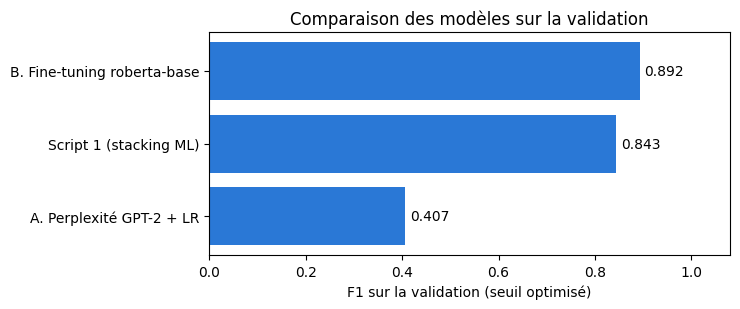

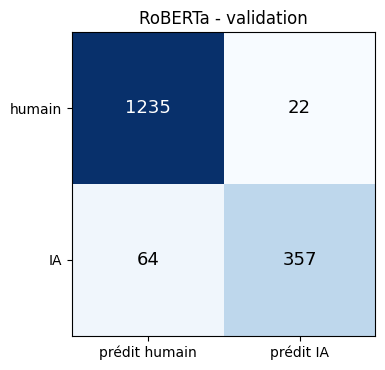

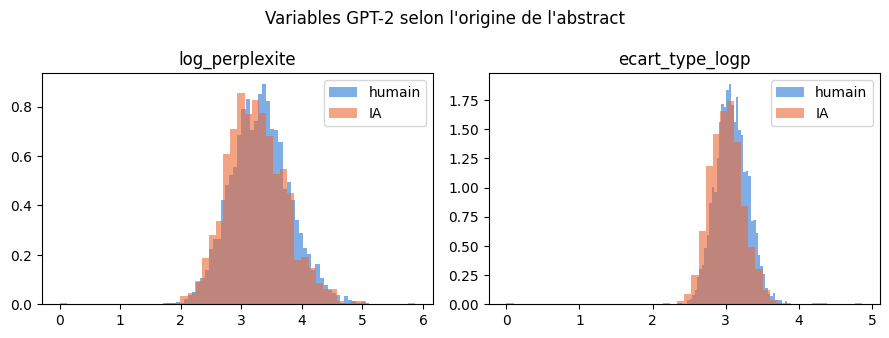

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

#comparaison des approches
plt.figure(figsize=(7.5, 3.2))
r = resultats.sort_values("F1")
plt.barh(r["modèle"], r["F1"], color="#2a78d6")
for i, v in enumerate(r["F1"]):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.xlim(0, 1.08); plt.xlabel("F1 sur la validation (seuil optimisé)")
plt.title("Comparaison des modèles sur la validation")
plt.tight_layout(); plt.savefig(os.path.join(dossier_figures, "fig1_comparaison.png"), dpi=200)
plt.show()

#matrice de confusion du modèle final (RoBERTa)
pred_val = (proba_val_final >= seuil_final).astype(int)
cm = confusion_matrix(y_val, pred_val)        #lignes = vérité, colonnes = prédiction
plt.figure(figsize=(4.5, 3.8))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
plt.xticks([0, 1], ["prédit humain", "prédit IA"]); plt.yticks([0, 1], ["humain", "IA"])
plt.title("RoBERTa - validation")
plt.tight_layout(); plt.savefig(os.path.join(dossier_figures, "fig2_matrice_confusion.png"), dpi=200)
plt.show()

#distribution des variables GPT-2 selon la classe
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, var in zip(axes, ["log_perplexite", "ecart_type_logp"]):
    ax.hist(P_app.loc[y_app == 0, var], bins=50, alpha=0.6, density=True, label="humain", color="#2a78d6")
    ax.hist(P_app.loc[y_app == 1, var], bins=50, alpha=0.6, density=True, label="IA", color="#eb6834")
    ax.set_title(var); ax.legend()
plt.suptitle("Variables GPT-2 selon l'origine de l'abstract")
plt.tight_layout(); plt.savefig(os.path.join(dossier_figures, "fig3_perplexite.png"), dpi=200)
plt.show()

## 6. prédiction du fichier de test
* On applique RoBERTa ajusté avec son seuil aux probabilités du test, ce qui donne **0 ou 1**. Les abstracts vides sont classés 1.
* On enregistre un fichier .csv à 2 colonnes `ID` et `pred`. Si le fichier test contient la colonne HumanAI, le F1 s'affiche directement.
* Une piste d'amélioration serait de réentraîner RoBERTa sur 100 % des données (apprentissage, réglage et validation) avec l'époque et le seuil retenus, avant de prédire le test.

In [12]:
pred_test = (proba_test_final >= seuil_final).astype(int)
vide_test = (test["texte"] == "").values
pred_test[vide_test] = 1                       #règle, un abstract vide est classé IA

#fichier de prédiction avec 2 colonnes, ID et pred
pd.DataFrame({"ID": test["ID"], "pred": pred_test}).to_csv(fichier_sortie, index=False)
print(f"{len(pred_test)} abstracts prédits dont {pred_test.sum()} IA ({pred_test.mean():.1%}), "
      f"dont {vide_test.sum()} vides -> {fichier_sortie}")

#si le fichier test contient les étiquettes, on affiche directement les performances
if COL_LABEL in test.columns:
    print(f"F1 = {f1_score(test[COL_LABEL], pred_test):.3f} | "
          f"précision = {precision_score(test[COL_LABEL], pred_test):.3f}")

2898 abstracts prédits dont 817 IA (28.2%), dont 223 vides -> predictions_script2.csv


## 7. conclusion

* On a comparé trois modèles sur le **même jeu de validation** (1 678 abstracts). L'époque et les seuils sont choisis sur un jeu de réglage séparé (671 abstracts), donc les F1 de validation sont des estimations indépendantes.
* **RoBERTa ajusté est notre modèle final**, avec un F1 de 0,892 (précision 0,942, rappel 0,848). Il fait 86 erreurs sur 1 678 abstracts, surtout des IA ratées (64) et peu de fausses alertes (22 humains classés IA). Sa meilleure époque sur le jeu de réglage est la 2e (F1 de 0,915 contre 0,903 à la 3e), la 3e montre un début de surapprentissage.
* Sur les mêmes abstracts et avec la même méthode, le script 1 obtient 0,843. C’est moins que son 0,865 en validation croisée, car il est évalué ici sur moins d’abstracts, avec un seuil choisi sur le jeu de réglage. Le deep learning apporte donc environ 5 points de F1.
* La perplexité GPT-2 ne marche pas (F1 de 0,407), sans doute parce que GPT-2, entraîné sur des textes du web, prédit mal le vocabulaire médical, que le texte soit écrit par un humain ou par une IA.
* Sur le fichier de test, 817 abstracts sont prédits IA (28,2 %), dont les 223 vides. Hors vides, cela fait 22,2 %, un peu moins que les 25 % d'IA de la validation, ce qui va avec une précision élevée. En comptant les vides, que la règle classe sans erreur, on peut estimer le F1 sur le test à environ **0,92**.
* Sur GPU, les résultats varient d'environ 1 point d'un lancement à l'autre (lors de nos lancements précédents, RoBERTa variait entre 0,884 et 0,906).

* Il y a quelques limites :
  * RoBERTa n'est entraîné que sur 6 039 abstracts (72 % des données), le reste servant au réglage et à la validation
  * le jeu de réglage est petit (671 abstracts), donc le choix du seuil reste un peu incertain
  * RoBERTa voit les mêmes artefacts de mise en forme que le script 1 (titres collés, apostrophes supprimées), et sa performance en dépend sans doute en partie
  * la généralisation à des LLM absents de l'entraînement n'est pas garantie